# CSE465 — Swin-T + RetinaNet (No Augmentation)

Transformer-based object detector baseline for the prepared PV-cell defect dataset.

**Architecture**
- Swin Transformer Tiny backbone (`torchvision.models.swin_t`)
- ImageNet-1K pretrained Swin-T backbone
- FPN using Swin stages at strides 8, 16 and 32
- RetinaNet detection head
- 9 PV-defect classes

**Training**
- Input size: 640 × 640
- Physical batch size: 4
- Gradient accumulation: 4
- Effective batch size: 16
- Maximum epochs: 50
- Early stopping patience: 5
- AMP enabled
- Seed: 42
- **No data augmentation**

Only deterministic letterbox resizing/padding is used. Letterboxing is preprocessing, not augmentation.

**Important:** the Swin-T backbone is ImageNet-pretrained. The FPN and RetinaNet detection head are initialized for this dataset and trained here.

Notebook:
`MyDrive/Colab Notebooks/CSE465/03_SwinT_RetinaNet_NoAug.ipynb`

Results:
`MyDrive/Study Materials /CSE465/03_SwinT_RetinaNet_NoAug/`

## 1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Install evaluation dependencies

In [ ]:
!pip install -q torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 21.4 MB/s eta 0:00:00


## 3. Imports and reproducibility

In [ ]:
import os
import gc
import cv2
import time
import math
import yaml
import random
import shutil
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from collections import OrderedDict, defaultdict

import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader

from torchvision.models import swin_t, Swin_T_Weights
from torchvision.models.detection.retinanet import RetinaNet
from torchvision.ops import FeaturePyramidNetwork, box_iou
from torchvision.ops.feature_pyramid_network import LastLevelP6P7
from torchvision.ops.stochastic_depth import StochasticDepth

from torchmetrics.detection.mean_ap import MeanAveragePrecision

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type != "cuda":
    raise RuntimeError("GPU is required. In Colab choose Runtime > Change runtime type > T4 GPU.")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU: Tesla T4


## 4. Drive folders

In [ ]:
CSE_ROOT = Path("/content/drive/MyDrive/Study Materials /CSE465")
DATA_ZIP = CSE_ROOT / "Prepared Dataset.zip"

EXP_ROOT = CSE_ROOT / "03_SwinT_RetinaNet_NoAug"
WEIGHTS_DIR = EXP_ROOT / "weights"
METRICS_DIR = EXP_ROOT / "metrics"
PLOTS_DIR = EXP_ROOT / "plots"
PREDICTIONS_DIR = EXP_ROOT / "predictions"
CONFIG_DIR = EXP_ROOT / "config"

for folder in [
    EXP_ROOT,
    WEIGHTS_DIR,
    METRICS_DIR,
    PLOTS_DIR,
    PREDICTIONS_DIR,
    CONFIG_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

BEST_PT = WEIGHTS_DIR / "best.pt"
LAST_PT = WEIGHTS_DIR / "last.pt"

assert DATA_ZIP.exists(), f"Dataset ZIP not found: {DATA_ZIP}"

print("Dataset:", DATA_ZIP)
print("Experiment:", EXP_ROOT)

Dataset: /content/drive/MyDrive/Study Materials /CSE465/Prepared Dataset.zip
Experiment: /content/drive/MyDrive/Study Materials /CSE465/03_SwinT_RetinaNet_NoAug


## 5. Extract prepared dataset locally

In [ ]:
import zipfile

LOCAL_ROOT = Path("/content/CSE465_dataset")

if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)

LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(DATA_ZIP, "r") as z:
    z.extractall(LOCAL_ROOT)

DATASET_DIR = LOCAL_ROOT / "Prepared Dataset"
DATA_YAML = DATASET_DIR / "data.yaml"

assert DATASET_DIR.exists()
assert DATA_YAML.exists()

print("Dataset extracted to:", DATASET_DIR)

Dataset extracted to: /content/CSE465_dataset/Prepared Dataset


## 6. Read dataset configuration

In [ ]:
with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

CLASS_NAMES = data_config["names"]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of detection classes:", NUM_CLASSES)

for split in ["train", "val", "test"]:
    n_img = len(list((DATASET_DIR / "images" / split).glob("*")))
    n_lbl = len(list((DATASET_DIR / "labels" / split).glob("*.txt")))
    print(f"{split:5s}: {n_img} images | {n_lbl} labels")

Classes: ['finger', 'crack', 'black_core', 'thick_line', 'horizontal_dislocation', 'short_circuit', 'vertical_dislocation', 'star_crack', 'printing_error']
Number of detection classes: 9
train: 4418 images | 4418 labels
val  : 947 images | 947 labels
test : 949 images | 949 labels


## 7. Training configuration

Start with physical batch **4** on a Colab T4.

If the first training batch gives CUDA OOM, change:
- `BATCH_SIZE = 2`
- `ACCUM_STEPS = 8`

The effective batch remains 16.

In [ ]:
IMAGE_SIZE = 640

BATCH_SIZE = 4
ACCUM_STEPS = 4
EFFECTIVE_BATCH = BATCH_SIZE * ACCUM_STEPS

MAX_EPOCHS = 50
PATIENCE = 5
NUM_WORKERS = 2

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.05
GRAD_CLIP = 1.0

AMP = True

CONF_THRESHOLD = 0.25
MATCH_IOU_THRESHOLD = 0.50

RESUME = False   # Change to True only after a disconnect/restart.

training_config = {
    "model": "Swin-T + FPN + RetinaNet",
    "experiment": "NoAug",
    "image_size": IMAGE_SIZE,
    "physical_batch_size": BATCH_SIZE,
    "gradient_accumulation": ACCUM_STEPS,
    "effective_batch_size": EFFECTIVE_BATCH,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED,
    "augmentation": "None",
    "backbone_pretraining": "ImageNet-1K",
}

with open(CONFIG_DIR / "training_config.yaml", "w") as f:
    yaml.safe_dump(training_config, f, sort_keys=False)

print(training_config)

{'model': 'Swin-T + FPN + RetinaNet', 'experiment': 'NoAug', 'image_size': 640, 'physical_batch_size': 4, 'gradient_accumulation': 4, 'effective_batch_size': 16, 'max_epochs': 50, 'patience': 5, 'learning_rate': 0.0001, 'weight_decay': 0.05, 'seed': 42, 'augmentation': 'None', 'backbone_pretraining': 'ImageNet-1K'}


## 8. Dataset class — deterministic preprocessing only

This cell performs:
1. image loading,
2. deterministic letterbox resize/padding to 640×640,
3. YOLO-label conversion to `[x1, y1, x2, y2]`,
4. tensor conversion.

There are **no random flips, rotations, color transforms, Mosaic, MixUp or other augmentations**.

In [ ]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def letterbox_image(image, boxes, size=640, fill=114):
    h, w = image.shape[:2]
    scale = min(size / w, size / h)

    new_w = int(round(w * scale))
    new_h = int(round(h * scale))

    resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    pad_x = (size - new_w) // 2
    pad_y = (size - new_h) // 2

    canvas = np.full((size, size, 3), fill, dtype=np.uint8)
    canvas[pad_y:pad_y + new_h, pad_x:pad_x + new_w] = resized

    if len(boxes):
        boxes = boxes.copy().astype(np.float32)
        boxes[:, [0, 2]] = boxes[:, [0, 2]] * scale + pad_x
        boxes[:, [1, 3]] = boxes[:, [1, 3]] * scale + pad_y

    return canvas, boxes


class PVDetectionDataset(Dataset):
    def __init__(self, dataset_dir, split, image_size=640):
        self.image_dir = Path(dataset_dir) / "images" / split
        self.label_dir = Path(dataset_dir) / "labels" / split
        self.image_size = image_size

        self.images = sorted(
            p for p in self.image_dir.iterdir()
            if p.suffix.lower() in IMAGE_EXTENSIONS
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_path = self.images[idx]
        label_path = self.label_dir / f"{image_path.stem}.txt"

        image = cv2.imread(str(image_path))
        if image is None:
            raise RuntimeError(f"Could not read: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = image.shape[:2]

        boxes = []
        labels = []

        if label_path.exists():
            text = label_path.read_text().strip()

            if text:
                for line in text.splitlines():
                    cls_id, xc, yc, bw, bh = map(float, line.split())

                    x1 = (xc - bw / 2) * w
                    y1 = (yc - bh / 2) * h
                    x2 = (xc + bw / 2) * w
                    y2 = (yc + bh / 2) * h

                    boxes.append([x1, y1, x2, y2])
                    labels.append(int(cls_id))

        boxes = np.asarray(boxes, dtype=np.float32).reshape(-1, 4)

        image, boxes = letterbox_image(
            image,
            boxes,
            size=self.image_size,
        )

        image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0

        target = {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32),
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([idx], dtype=torch.int64),
        }

        return image, target, str(image_path)


def collate_fn(batch):
    images, targets, paths = zip(*batch)
    return list(images), list(targets), list(paths)


train_dataset = PVDetectionDataset(DATASET_DIR, "train", IMAGE_SIZE)
val_dataset = PVDetectionDataset(DATASET_DIR, "val", IMAGE_SIZE)
test_dataset = PVDetectionDataset(DATASET_DIR, "test", IMAGE_SIZE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))
print("Physical batch:", BATCH_SIZE)
print("Effective batch:", EFFECTIVE_BATCH)

Train: 4418
Val  : 947
Test : 949
Physical batch: 4
Effective batch: 16


## 9. Build Swin-T + FPN + RetinaNet

In [ ]:
class SwinTinyFPN(nn.Module):
    def __init__(self, pretrained=True, out_channels=256):
        super().__init__()

        weights = Swin_T_Weights.DEFAULT if pretrained else None
        base = swin_t(weights=weights)

        # Swin feature stages:
        # stage 2 -> stride 8,  channels 192
        # stage 3 -> stride 16, channels 384
        # stage 4 -> stride 32, channels 768
        self.features = base.features

        self.fpn = FeaturePyramidNetwork(
            in_channels_list=[192, 384, 768],
            out_channels=out_channels,
            extra_blocks=LastLevelP6P7(768, out_channels),
        )

        self.out_channels = out_channels

    def forward(self, x):
        y = x
        features = OrderedDict()
        level = 0

        for i, layer in enumerate(self.features):
            y = layer(y)

            if i in (3, 5, 7):
                # Torchvision Swin stages are NHWC.
                features[str(level)] = y.permute(0, 3, 1, 2).contiguous()
                level += 1

        return self.fpn(features)


def build_model():
    backbone = SwinTinyFPN(pretrained=True)

    model = RetinaNet(
        backbone=backbone,
        num_classes=NUM_CLASSES,
        min_size=IMAGE_SIZE,
        max_size=IMAGE_SIZE,
        image_mean=[0.485, 0.456, 0.406],
        image_std=[0.229, 0.224, 0.225],
        score_thresh=0.001,
        detections_per_img=100,
    )

    return model


model = build_model().to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters    : {total_params:,} ({total_params/1e6:.3f} M)")
print(f"Trainable parameters: {trainable_params:,} ({trainable_params/1e6:.3f} M)")

Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 172MB/s]


Total parameters    : 36,983,023 (36.983 M)
Trainable parameters: 36,983,023 (36.983 M)


## 10. Optimizer, scheduler and AMP

AdamW is used because it is a standard optimizer for Transformer fine-tuning.

`ACCUM_STEPS=4` with physical batch 4 gives an effective batch of 16.

In [ ]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=1e-6,
)

try:
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
except TypeError:
    scaler = torch.cuda.amp.GradScaler(enabled=AMP)

def autocast_context():
    try:
        return torch.amp.autocast("cuda", enabled=AMP)
    except TypeError:
        return torch.cuda.amp.autocast(enabled=AMP)

print("Optimizer: AdamW")
print("AMP:", AMP)

Optimizer: AdamW
AMP: True


## 11. Training and validation helpers

In [ ]:
def move_targets_to_device(targets):
    return [
        {k: v.to(DEVICE, non_blocking=True) for k, v in t.items()}
        for t in targets
    ]


@torch.no_grad()
def compute_validation_loss(model, loader):
    # Torchvision detection models return losses only in training mode.
    # StochasticDepth is explicitly disabled to keep validation deterministic.
    model.train()

    for module in model.modules():
        if isinstance(module, StochasticDepth):
            module.eval()

    total_cls = 0.0
    total_box = 0.0
    total_images = 0

    start = time.perf_counter()

    for images, targets, _ in loader:
        images = [img.to(DEVICE, non_blocking=True) for img in images]
        targets = move_targets_to_device(targets)

        with autocast_context():
            losses = model(images, targets)

        batch_n = len(images)

        total_cls += float(losses["classification"].detach()) * batch_n
        total_box += float(losses["bbox_regression"].detach()) * batch_n
        total_images += batch_n

    torch.cuda.synchronize()
    seconds = time.perf_counter() - start

    model.eval()

    cls_loss = total_cls / max(total_images, 1)
    box_loss = total_box / max(total_images, 1)

    return {
        "classification_loss": cls_loss,
        "bbox_regression_loss": box_loss,
        "total_loss": cls_loss + box_loss,
        "seconds": seconds,
    }


@torch.no_grad()
def evaluate_map(model, loader):
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=False,
    )

    start = time.perf_counter()

    for images, targets, _ in loader:
        images_gpu = [img.to(DEVICE, non_blocking=True) for img in images]

        with autocast_context():
            outputs = model(images_gpu)

        preds = [
            {
                "boxes": out["boxes"].detach().cpu(),
                "scores": out["scores"].detach().cpu(),
                "labels": out["labels"].detach().cpu(),
            }
            for out in outputs
        ]

        gts = [
            {
                "boxes": t["boxes"].detach().cpu(),
                "labels": t["labels"].detach().cpu(),
            }
            for t in targets
        ]

        metric.update(preds, gts)

    torch.cuda.synchronize()
    seconds = time.perf_counter() - start

    result = metric.compute()

    return {
        "map50": float(result["map_50"]),
        "map75": float(result["map_75"]),
        "map50_95": float(result["map"]),
        "seconds": seconds,
    }

# 13. Train Fresh / Resume

## 13A. Resume support

For a **fresh run**, leave:

```python
RESUME = False
```

After a Colab disconnect:
1. reconnect to GPU,
2. rerun setup cells,
3. set `RESUME = True`,
4. rerun from the model/optimizer cells onward.

`last.pt` is overwritten each epoch, so duplicate checkpoints are not created.

In [ ]:
history = []
start_epoch = 1
best_map = -1.0
best_epoch = 0
epochs_without_improvement = 0

if RESUME:
    if not LAST_PT.exists():
        raise FileNotFoundError(f"No resume checkpoint found: {LAST_PT}")

    checkpoint = torch.load(LAST_PT, map_location=DEVICE)

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scheduler.load_state_dict(checkpoint["scheduler_state"])

    if "scaler_state" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state"])

    start_epoch = int(checkpoint["epoch"]) + 1
    best_map = float(checkpoint["best_map"])
    best_epoch = int(checkpoint["best_epoch"])
    epochs_without_improvement = int(checkpoint["epochs_without_improvement"])
    history = checkpoint.get("history", [])

    print(f"Resuming from epoch {start_epoch}")
else:
    if LAST_PT.exists():
        raise RuntimeError(
            "Existing last.pt found. "
            "Set RESUME=True to continue, or use a new/empty experiment folder."
        )

    print("Starting a fresh Swin-T + RetinaNet run.")

Starting a fresh Swin-T + RetinaNet run.


## 13B. Train Fresh

The model is selected using **validation mAP@50–95**.

Early stopping:
- maximum 50 epochs,
- patience 5.

Exact train, validation-loss and validation-mAP times are saved after every epoch.

In [ ]:
# 13. TRAIN — LIVE EPOCH/BATCH PROGRESS

from tqdm.auto import tqdm

for epoch in range(start_epoch, MAX_EPOCHS + 1):

    model.train()

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    epoch_start = time.perf_counter()

    train_cls_sum = 0.0
    train_box_sum = 0.0
    train_images = 0

    optimizer.zero_grad(set_to_none=True)

    n_steps = len(train_loader)

    # ------------------------------------------------
    # LIVE TRAINING PROGRESS BAR
    # ------------------------------------------------
    train_bar = tqdm(
        enumerate(train_loader),
        total=n_steps,
        desc=f"Epoch {epoch}/{MAX_EPOCHS}",
        dynamic_ncols=True
    )

    for step, (images, targets, _) in train_bar:

        images = [
            img.to(DEVICE, non_blocking=True)
            for img in images
        ]

        targets = move_targets_to_device(targets)

        # Gradient accumulation
        group_start = (step // ACCUM_STEPS) * ACCUM_STEPS
        group_end = min(group_start + ACCUM_STEPS, n_steps)
        group_size = group_end - group_start

        with autocast_context():

            losses = model(images, targets)

            cls_loss = losses["classification"]
            box_loss = losses["bbox_regression"]

            total_loss = cls_loss + box_loss

            scaled_loss = total_loss / group_size

        scaler.scale(scaled_loss).backward()

        # Optimizer update
        if step == group_end - 1:

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)

        batch_n = len(images)

        train_cls_sum += float(cls_loss.detach()) * batch_n
        train_box_sum += float(box_loss.detach()) * batch_n
        train_images += batch_n

        # ------------------------------
        # LIVE DISPLAY
        # ------------------------------
        train_bar.set_postfix({
            "loss": f"{float(total_loss.detach()):.4f}",
            "cls": f"{float(cls_loss.detach()):.4f}",
            "box": f"{float(box_loss.detach()):.4f}",
            "VRAM": f"{torch.cuda.memory_allocated()/1024**3:.1f}G"
        })

    torch.cuda.synchronize()

    train_seconds = time.perf_counter() - epoch_start

    train_cls = train_cls_sum / train_images
    train_box = train_box_sum / train_images
    train_total = train_cls + train_box


    # ------------------------------------------------
    # VALIDATION LOSS
    # ------------------------------------------------
    print("\nCalculating validation loss...")

    val_loss_result = compute_validation_loss(
        model,
        val_loader
    )


    # ------------------------------------------------
    # VALIDATION mAP
    # ------------------------------------------------
    print("Calculating validation mAP...")

    val_map_result = evaluate_map(
        model,
        val_loader
    )

    scheduler.step()


    # ------------------------------------------------
    # TIMING
    # ------------------------------------------------
    total_seconds = (
        train_seconds
        + val_loss_result["seconds"]
        + val_map_result["seconds"]
    )

    peak_vram_gb = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )


    # ------------------------------------------------
    # SAVE HISTORY
    # ------------------------------------------------
    record = {

        "epoch": epoch,

        "train/classification_loss": train_cls,
        "train/bbox_regression_loss": train_box,
        "train/total_loss": train_total,

        "val/classification_loss":
            val_loss_result["classification_loss"],

        "val/bbox_regression_loss":
            val_loss_result["bbox_regression_loss"],

        "val/total_loss":
            val_loss_result["total_loss"],

        "val/mAP50":
            val_map_result["map50"],

        "val/mAP75":
            val_map_result["map75"],

        "val/mAP50-95":
            val_map_result["map50_95"],

        "train_seconds":
            train_seconds,

        "val_loss_seconds":
            val_loss_result["seconds"],

        "val_map_seconds":
            val_map_result["seconds"],

        "total_seconds":
            total_seconds,

        "lr":
            optimizer.param_groups[0]["lr"],

        "peak_vram_GB":
            peak_vram_gb,
    }

    history.append(record)

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        METRICS_DIR / "training_history.csv",
        index=False
    )


    # ------------------------------------------------
    # EARLY STOPPING / BEST MODEL
    # ------------------------------------------------
    current_map = val_map_result["map50_95"]

    improved = current_map > best_map

    if improved:

        best_map = current_map
        best_epoch = epoch
        epochs_without_improvement = 0

        best_state = {

            "epoch": epoch,
            "best_map50_95": best_map,

            "model_state": {
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            },

            "class_names": CLASS_NAMES,
            "training_config": training_config,
        }

        torch.save(
            best_state,
            BEST_PT
        )

    else:

        epochs_without_improvement += 1


    # ------------------------------------------------
    # LAST CHECKPOINT FOR RESUME
    # ------------------------------------------------
    last_state = {

        "epoch": epoch,

        "model_state":
            model.state_dict(),

        "optimizer_state":
            optimizer.state_dict(),

        "scheduler_state":
            scheduler.state_dict(),

        "scaler_state":
            scaler.state_dict(),

        "best_map":
            best_map,

        "best_epoch":
            best_epoch,

        "epochs_without_improvement":
            epochs_without_improvement,

        "history":
            history,

        "training_config":
            training_config,
    }

    torch.save(
        last_state,
        LAST_PT
    )


    # ------------------------------------------------
    # EPOCH SUMMARY
    # ------------------------------------------------
    print("\n" + "=" * 70)

    print(f"EPOCH {epoch}/{MAX_EPOCHS} COMPLETE")

    print("-" * 70)

    print(
        f"Train Loss    : {train_total:.4f} "
        f"(Cls {train_cls:.4f} | Box {train_box:.4f})"
    )

    print(
        f"Val Loss      : "
        f"{val_loss_result['total_loss']:.4f}"
    )

    print(
        f"Val mAP@50    : "
        f"{val_map_result['map50']:.4f}"
    )

    print(
        f"Val mAP@75    : "
        f"{val_map_result['map75']:.4f}"
    )

    print(
        f"Val mAP@50-95 : "
        f"{current_map:.4f}"
    )

    print("-" * 70)

    print(
        f"Train time    : "
        f"{train_seconds/60:.2f} min"
    )

    print(
        f"Val-loss time : "
        f"{val_loss_result['seconds']/60:.2f} min"
    )

    print(
        f"Val-mAP time  : "
        f"{val_map_result['seconds']/60:.2f} min"
    )

    print(
        f"Total epoch   : "
        f"{total_seconds/60:.2f} min"
    )

    print(
        f"Peak VRAM     : "
        f"{peak_vram_gb:.2f} GB"
    )

    print("-" * 70)

    print(
        f"Best epoch    : {best_epoch}"
    )

    print(
        f"Best mAP50-95 : {best_map:.4f}"
    )

    print(
        f"Early stopping: "
        f"{epochs_without_improvement}/{PATIENCE}"
    )

    print("=" * 70)


    # ------------------------------------------------
    # EARLY STOPPING
    # ------------------------------------------------
    if epochs_without_improvement >= PATIENCE:

        print(
            f"\nEarly stopping triggered at epoch {epoch}."
        )

        break


print("\nTRAINING FINISHED")
print("Best epoch:", best_epoch)
print(
    "Best validation mAP@50-95:",
    round(best_map, 4)
)

Epoch 1/50:   0%|          | 0/1105 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 1/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 1.1013 (Cls 0.5539 | Box 0.5474)
Val Loss      : 0.7046
Val mAP@50    : 0.3609
Val mAP@75    : 0.1559
Val mAP@50-95 : 0.1797
----------------------------------------------------------------------
Train time    : 5.70 min
Val-loss time : 0.48 min
Val-mAP time  : 0.55 min
Total epoch   : 6.73 min
Peak VRAM     : 3.18 GB
----------------------------------------------------------------------
Best epoch    : 1
Best mAP50-95 : 0.1797
Early stopping: 0/5


Epoch 2/50:   0%|          | 0/1105 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 2/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.6875 (Cls 0.3154 | Box 0.3722)
Val Loss      : 0.6433
Val mAP@50    : 0.4990
Val mAP@75    : 0.1946
Val mAP@50-95 : 0.2527
----------------------------------------------------------------------
Train time    : 5.71 min
Val-loss time : 0.48 min
Val-mAP time  : 0.54 min
Total epoch   : 6.73 min
Peak VRAM     : 3.18 GB
----------------------------------------------------------------------
Best epoch    : 2
Best mAP50-95 : 0.2527
Early stopping: 0/5


Epoch 3/50:   0%|          | 0/1105 [00:00<?, ?it/s]

...


Calculating validation loss...
Calculating validation mAP...

EPOCH 31/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.1208 (Cls 0.0494 | Box 0.0714)
Val Loss      : 1.1483
Val mAP@50    : 0.9016
Val mAP@75    : 0.5669
Val mAP@50-95 : 0.5764
----------------------------------------------------------------------
Train time    : 5.64 min
Val-loss time : 0.47 min
Val-mAP time  : 0.52 min
Total epoch   : 6.63 min
Peak VRAM     : 3.17 GB
----------------------------------------------------------------------
Best epoch    : 28
Best mAP50-95 : 0.5848
Early stopping: 3/5


Epoch 32/50:   0%|          | 0/1105 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 32/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.1152 (Cls 0.0478 | Box 0.0674)
Val Loss      : 1.0982
Val mAP@50    : 0.9035
Val mAP@75    : 0.6180
Val mAP@50-95 : 0.5803
----------------------------------------------------------------------
Train time    : 5.64 min
Val-loss time : 0.47 min
Val-mAP time  : 0.52 min
Total epoch   : 6.64 min
Peak VRAM     : 3.18 GB
----------------------------------------------------------------------
Best epoch    : 28
Best mAP50-95 : 0.5848
Early stopping: 4/5


Epoch 33/50:   0%|          | 0/1105 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 33/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.1117 (Cls 0.0457 | Box 0.0660)
Val Loss      : 1.2147
Val mAP@50    : 0.9031
Val mAP@75    : 0.5657
Val mAP@50-95 : 0.5763
----------------------------------------------------------------------
Train time    : 5.64 min
Val-loss time : 0.47 min
Val-mAP time  : 0.52 min
Total epoch   : 6.63 min
Peak VRAM     : 3.18 GB
----------------------------------------------------------------------
Best epoch    : 28
Best mAP50-95 : 0.5848
Early stopping: 5/5

Early stopping triggered at epoch 33.

TRAINING FINISHED
Best epoch: 28
Best validation mAP@50-95: 0.5848


# Results

## 14. Training history and timing summary

In [ ]:
history_df = pd.read_csv(METRICS_DIR / "training_history.csv")

epochs_completed = int(history_df["epoch"].max())
best_row = history_df.loc[history_df["val/mAP50-95"].idxmax()]
best_epoch = int(best_row["epoch"])

timing_summary = pd.DataFrame([{
    "epochs_completed": epochs_completed,
    "best_epoch": best_epoch,
    "mean_train_min_per_epoch": history_df["train_seconds"].mean() / 60,
    "mean_val_loss_min_per_epoch": history_df["val_loss_seconds"].mean() / 60,
    "mean_val_map_min_per_epoch": history_df["val_map_seconds"].mean() / 60,
    "mean_total_min_per_epoch": history_df["total_seconds"].mean() / 60,
    "total_training_run_min": history_df["total_seconds"].sum() / 60,
    "mean_peak_vram_GB": history_df["peak_vram_GB"].mean(),
    "max_peak_vram_GB": history_df["peak_vram_GB"].max(),
}]).round(4)

timing_summary.to_csv(
    METRICS_DIR / "timing_summary.csv",
    index=False,
)

display(timing_summary)

,epochs_completed,best_epoch,mean_train_min_per_epoch,mean_val_loss_min_per_epoch,mean_val_map_min_per_epoch,mean_total_min_per_epoch,total_training_run_min,mean_peak_vram_GB,max_peak_vram_GB
0,33,28,5.6719,0.4729,0.5383,6.6831,220.5429,3.1761,3.1786


## 15. Training vs validation loss curves

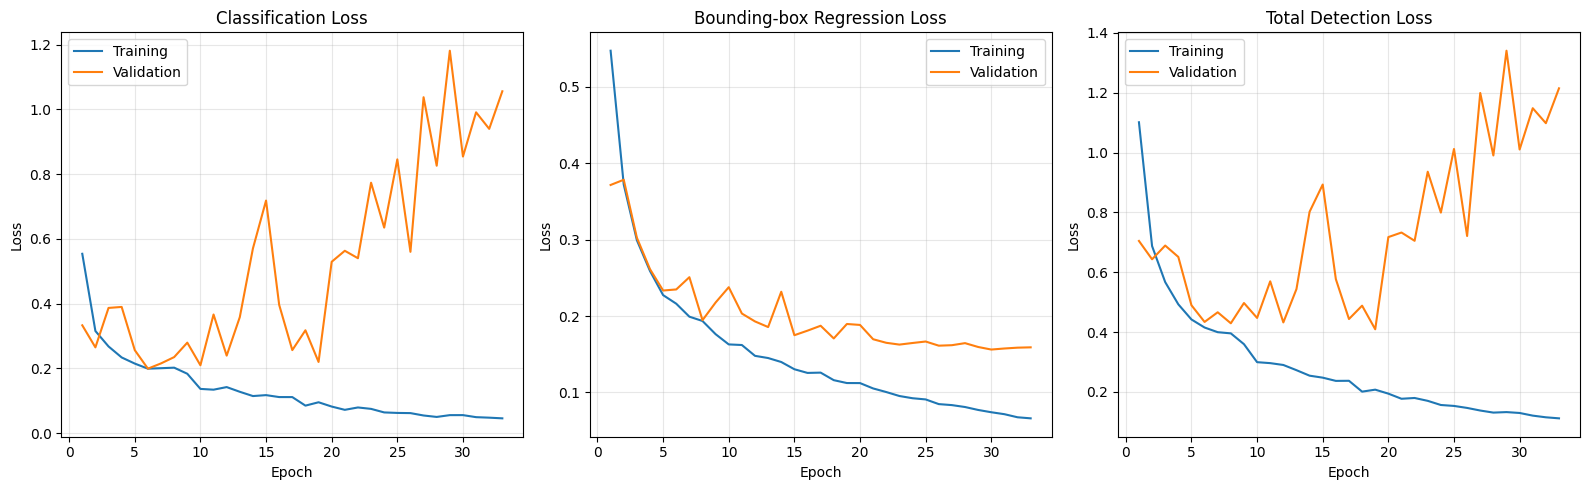

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

loss_pairs = [
    (
        "train/classification_loss",
        "val/classification_loss",
        "Classification Loss",
    ),
    (
        "train/bbox_regression_loss",
        "val/bbox_regression_loss",
        "Bounding-box Regression Loss",
    ),
    (
        "train/total_loss",
        "val/total_loss",
        "Total Detection Loss",
    ),
]

for ax, (train_col, val_col, title) in zip(axes, loss_pairs):
    ax.plot(history_df["epoch"], history_df[train_col], label="Training")
    ax.plot(history_df["epoch"], history_df[val_col], label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "training_validation_loss_curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 16. Validation mAP vs epoch

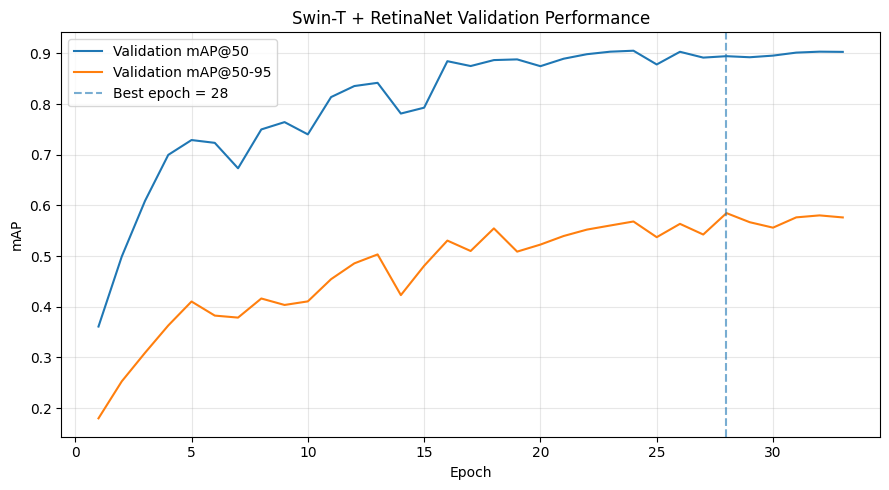

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["val/mAP50"],
    label="Validation mAP@50",
)

plt.plot(
    history_df["epoch"],
    history_df["val/mAP50-95"],
    label="Validation mAP@50-95",
)

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best epoch = {best_epoch}",
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Swin-T + RetinaNet Validation Performance")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "validation_map_vs_epoch.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 17. Load the best model for final test evaluation

In [ ]:
best_checkpoint = torch.load(BEST_PT, map_location="cpu")

model.load_state_dict(best_checkpoint["model_state"])
model = model.to(DEVICE)
model.eval()

gc.collect()
torch.cuda.empty_cache()

print(
    f"Loaded best model from epoch "
    f"{best_checkpoint['epoch']} "
    f"(val mAP50-95={best_checkpoint['best_map50_95']:.4f})"
)

Loaded best model from epoch 28 (val mAP50-95=0.5848)


## 18. Collect test predictions once

In [ ]:
@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()

    predictions = []
    targets_all = []
    paths_all = []

    total_forward_seconds = 0.0
    total_images = 0

    for images, targets, paths in loader:
        images_gpu = [img.to(DEVICE, non_blocking=True) for img in images]

        torch.cuda.synchronize()
        start = time.perf_counter()

        with autocast_context():
            outputs = model(images_gpu)

        torch.cuda.synchronize()
        total_forward_seconds += time.perf_counter() - start
        total_images += len(images)

        for out in outputs:
            predictions.append({
                "boxes": out["boxes"].detach().cpu(),
                "scores": out["scores"].detach().cpu(),
                "labels": out["labels"].detach().cpu(),
            })

        for target in targets:
            targets_all.append({
                "boxes": target["boxes"].detach().cpu(),
                "labels": target["labels"].detach().cpu(),
            })

        paths_all.extend(paths)

    inference_ms = (
        total_forward_seconds / max(total_images, 1) * 1000
    )

    return predictions, targets_all, paths_all, inference_ms


test_predictions, test_targets, test_paths, inference_ms = collect_predictions(
    model,
    test_loader,
)

fps = 1000 / inference_ms if inference_ms > 0 else np.nan

print("Test images:", len(test_predictions))
print(f"Model forward time: {inference_ms:.3f} ms/image")
print(f"FPS: {fps:.2f}")

Test images: 949
Model forward time: 38.738 ms/image
FPS: 25.81


## 19. Test mAP50, mAP75 and mAP50–95

In [ ]:
map_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
)

map50_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    iou_thresholds=[0.50],
    class_metrics=True,
)

map_metric.update(test_predictions, test_targets)
map50_metric.update(test_predictions, test_targets)

map_result = map_metric.compute()
map50_result = map50_metric.compute()

test_map50 = float(map_result["map_50"])
test_map75 = float(map_result["map_75"])
test_map50_95 = float(map_result["map"])

print(f"mAP@50    : {test_map50:.4f}")
print(f"mAP@75    : {test_map75:.4f}")
print(f"mAP@50-95 : {test_map50_95:.4f}")

## 20. Precision, Recall, F1, matched box IoU and Dice

For threshold metrics:
- confidence ≥ 0.25
- class-aware one-to-one matching
- TP IoU threshold = 0.50

The IoU and Dice values below are **bounding-box overlap metrics**, not segmentation-mask metrics.

In [ ]:
def class_aware_matches(pred, gt, conf_threshold=0.25, iou_threshold=0.50):
    keep = pred["scores"] >= conf_threshold

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    if len(p_boxes) == 0 or len(g_boxes) == 0:
        return [], p_boxes, p_labels

    ious = box_iou(p_boxes, g_boxes)

    candidates = []

    for pi in range(len(p_boxes)):
        for gi in range(len(g_boxes)):
            if int(p_labels[pi]) != int(g_labels[gi]):
                continue

            iou = float(ious[pi, gi])

            if iou >= iou_threshold:
                candidates.append((iou, pi, gi))

    candidates.sort(reverse=True)

    used_pred = set()
    used_gt = set()
    matches = []

    for iou, pi, gi in candidates:
        if pi in used_pred or gi in used_gt:
            continue

        used_pred.add(pi)
        used_gt.add(gi)
        matches.append((pi, gi, iou))

    return matches, p_boxes, p_labels


overall_tp = overall_fp = overall_fn = 0
matched_ious = []

per_class_counts = defaultdict(
    lambda: {
        "tp": 0,
        "fp": 0,
        "fn": 0,
        "ious": [],
    }
)

for pred, gt in zip(test_predictions, test_targets):

    matches, p_boxes, p_labels = class_aware_matches(
        pred,
        gt,
        CONF_THRESHOLD,
        MATCH_IOU_THRESHOLD,
    )

    matched_p = {m[0] for m in matches}
    matched_g = {m[1] for m in matches}

    tp = len(matches)
    fp = len(p_boxes) - tp
    fn = len(gt["boxes"]) - tp

    overall_tp += tp
    overall_fp += fp
    overall_fn += fn

    for pi, gi, iou in matches:
        cls_id = int(gt["labels"][gi])

        matched_ious.append(iou)

        per_class_counts[cls_id]["tp"] += 1
        per_class_counts[cls_id]["ious"].append(iou)

    for pi, cls_id in enumerate(p_labels.tolist()):
        if pi not in matched_p:
            per_class_counts[int(cls_id)]["fp"] += 1

    for gi, cls_id in enumerate(gt["labels"].tolist()):
        if gi not in matched_g:
            per_class_counts[int(cls_id)]["fn"] += 1


test_precision = (
    overall_tp / (overall_tp + overall_fp)
    if overall_tp + overall_fp else 0.0
)

test_recall = (
    overall_tp / (overall_tp + overall_fn)
    if overall_tp + overall_fn else 0.0
)

test_f1 = (
    2 * test_precision * test_recall
    / (test_precision + test_recall)
    if test_precision + test_recall else 0.0
)

mean_iou = (
    float(np.mean(matched_ious))
    if matched_ious else np.nan
)

matched_dices = [
    2 * iou / (1 + iou)
    for iou in matched_ious
]

mean_dice = (
    float(np.mean(matched_dices))
    if matched_dices else np.nan
)

print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1        : {test_f1:.4f}")
print(f"TP / FP / FN: {overall_tp} / {overall_fp} / {overall_fn}")
print(f"Mean matched box IoU : {mean_iou:.4f}")
print(f"Mean matched box Dice: {mean_dice:.4f}")

## 21. Per-class test performance

In [ ]:
map95_by_class = {}
map50_by_class = {}

classes95 = map_result["classes"].cpu().numpy().astype(int)
values95 = map_result["map_per_class"].cpu().numpy()

for cls_id, value in zip(classes95, values95):
    map95_by_class[int(cls_id)] = (
        float(value) if value >= 0 else np.nan
    )

classes50 = map50_result["classes"].cpu().numpy().astype(int)
values50 = map50_result["map_per_class"].cpu().numpy()

for cls_id, value in zip(classes50, values50):
    map50_by_class[int(cls_id)] = (
        float(value) if value >= 0 else np.nan
    )


class_image_counts = defaultdict(set)
class_instance_counts = defaultdict(int)

for image_idx, target in enumerate(test_targets):
    for cls_id in target["labels"].tolist():
        class_image_counts[int(cls_id)].add(image_idx)
        class_instance_counts[int(cls_id)] += 1


rows = []

for cls_id, class_name in enumerate(CLASS_NAMES):

    stats = per_class_counts[cls_id]

    tp = stats["tp"]
    fp = stats["fp"]
    fn = stats["fn"]

    p = tp / (tp + fp) if tp + fp else np.nan
    r = tp / (tp + fn) if tp + fn else np.nan

    f1 = (
        2 * p * r / (p + r)
        if np.isfinite(p)
        and np.isfinite(r)
        and p + r > 0
        else np.nan
    )

    cls_iou = (
        float(np.mean(stats["ious"]))
        if stats["ious"]
        else np.nan
    )

    cls_dice = (
        2 * cls_iou / (1 + cls_iou)
        if np.isfinite(cls_iou)
        else np.nan
    )

    rows.append({
        "Class": class_name,
        "Images": len(class_image_counts[cls_id]),
        "Instances": class_instance_counts[cls_id],
        "Box-P": p,
        "Box-R": r,
        "Box-F1": f1,
        "mAP50": map50_by_class.get(cls_id, np.nan),
        "mAP50-95": map95_by_class.get(cls_id, np.nan),
        "Mean Box IoU": cls_iou,
        "Mean Box Dice": cls_dice,
    })


per_class_df = pd.DataFrame(rows).round(4)

per_class_df.to_csv(
    METRICS_DIR / "final_per_class_summary.csv",
    index=False,
)

display(per_class_df)

## 22. Raw and normalized confusion matrices

In [ ]:
N = NUM_CLASSES
BG = N

confusion = np.zeros((N + 1, N + 1), dtype=np.int64)

for pred, gt in zip(test_predictions, test_targets):

    keep = pred["scores"] >= CONF_THRESHOLD

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    if len(p_boxes) and len(g_boxes):
        ious = box_iou(p_boxes, g_boxes)

        candidates = []

        for pi in range(len(p_boxes)):
            for gi in range(len(g_boxes)):
                iou = float(ious[pi, gi])

                if iou >= MATCH_IOU_THRESHOLD:
                    candidates.append((iou, pi, gi))

        candidates.sort(reverse=True)

        used_p = set()
        used_g = set()

        for iou, pi, gi in candidates:
            if pi in used_p or gi in used_g:
                continue

            used_p.add(pi)
            used_g.add(gi)

            confusion[
                int(g_labels[gi]),
                int(p_labels[pi])
            ] += 1

    else:
        used_p = set()
        used_g = set()

    for gi, cls_id in enumerate(g_labels.tolist()):
        if gi not in used_g:
            confusion[int(cls_id), BG] += 1

    for pi, cls_id in enumerate(p_labels.tolist()):
        if pi not in used_p:
            confusion[BG, int(cls_id)] += 1


labels_cm = CLASS_NAMES + ["background"]

row_sums = confusion.sum(axis=1, keepdims=True)

normalized = np.divide(
    confusion,
    row_sums,
    out=np.zeros_like(confusion, dtype=float),
    where=row_sums != 0,
)

pd.DataFrame(
    confusion,
    index=labels_cm,
    columns=labels_cm,
).to_csv(METRICS_DIR / "confusion_matrix.csv")

pd.DataFrame(
    normalized,
    index=labels_cm,
    columns=labels_cm,
).to_csv(METRICS_DIR / "confusion_matrix_normalized.csv")


def plot_confusion(matrix, title, filename, fmt):
    fig, ax = plt.subplots(figsize=(11, 9))

    im = ax.imshow(matrix)

    ax.set_xticks(range(len(labels_cm)))
    ax.set_yticks(range(len(labels_cm)))

    ax.set_xticklabels(labels_cm, rotation=45, ha="right")
    ax.set_yticklabels(labels_cm)

    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Ground-truth class")
    ax.set_title(title)

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix[i, j]

            text = (
                f"{value:.2f}"
                if fmt == "float"
                else str(int(value))
            )

            if value != 0:
                ax.text(
                    j,
                    i,
                    text,
                    ha="center",
                    va="center",
                    fontsize=7,
                )

    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


plot_confusion(
    confusion,
    "Swin-T + RetinaNet Confusion Matrix",
    "confusion_matrix.png",
    "int",
)

plot_confusion(
    normalized,
    "Swin-T + RetinaNet Normalized Confusion Matrix",
    "confusion_matrix_normalized.png",
    "float",
)

## 23. Ground Truth vs Prediction

In [ ]:
from matplotlib.patches import Rectangle

def show_box(ax, box, label, linewidth=1.5):
    x1, y1, x2, y2 = box

    rect = Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=linewidth,
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        max(10, y1),
        label,
        fontsize=7,
        bbox=dict(facecolor="white", alpha=0.65, edgecolor="none"),
    )


defect_indices = [
    i
    for i, target in enumerate(test_targets)
    if len(target["boxes"]) > 0
]

random.seed(SEED)
sample_indices = random.sample(
    defect_indices,
    min(6, len(defect_indices)),
)

fig, axes = plt.subplots(
    len(sample_indices),
    2,
    figsize=(12, 4 * len(sample_indices)),
)

if len(sample_indices) == 1:
    axes = np.array([axes])

for row, idx in enumerate(sample_indices):

    image_tensor, gt, _ = test_dataset[idx]

    image_np = (
        image_tensor.permute(1, 2, 0)
        .numpy()
        .clip(0, 1)
    )

    pred = test_predictions[idx]

    # Ground truth
    axes[row, 0].imshow(image_np)

    for box, cls_id in zip(
        gt["boxes"].numpy(),
        gt["labels"].numpy(),
    ):
        show_box(
            axes[row, 0],
            box,
            CLASS_NAMES[int(cls_id)],
        )

    axes[row, 0].set_title("Ground Truth")
    axes[row, 0].axis("off")

    # Prediction
    axes[row, 1].imshow(image_np)

    keep = pred["scores"] >= CONF_THRESHOLD

    for box, cls_id, score in zip(
        pred["boxes"][keep].numpy(),
        pred["labels"][keep].numpy(),
        pred["scores"][keep].numpy(),
    ):
        show_box(
            axes[row, 1],
            box,
            f"{CLASS_NAMES[int(cls_id)]} {score:.2f}",
        )

    axes[row, 1].set_title("Swin-T + RetinaNet Prediction")
    axes[row, 1].axis("off")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "ground_truth_vs_prediction.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 24. Model complexity

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

model_size_mb = (
    BEST_PT.stat().st_size / 1024**2
    if BEST_PT.exists()
    else np.nan
)

model_info_df = pd.DataFrame([{
    "model": "Swin-T + FPN + RetinaNet",
    "parameters": total_params,
    "parameters_M": total_params / 1e6,
    "trainable_parameters": trainable_params,
    "trainable_parameters_M": trainable_params / 1e6,
    "best_checkpoint_size_MB": model_size_mb,
}]).round(4)

model_info_df.to_csv(
    METRICS_DIR / "model_info.csv",
    index=False,
)

display(model_info_df)

,model,parameters,parameters_M,trainable_parameters,trainable_parameters_M,best_checkpoint_size_MB
0,Swin-T + FPN + RetinaNet,36983023,36.983,36983023,36.983,141.3519


# 25. Final model summary

This cell only summarizes results already calculated above.  
It does **not** retrain or re-run the test set.

In [ ]:
history_df = pd.read_csv(
    METRICS_DIR / "training_history.csv"
)

epochs_completed = int(history_df["epoch"].max())

best_epoch = int(
    history_df.loc[
        history_df["val/mAP50-95"].idxmax(),
        "epoch",
    ]
)

early_stopped = epochs_completed < MAX_EPOCHS

final_summary_df = pd.DataFrame([{
    "Model": "Swin-T + FPN + RetinaNet",
    "Experiment": "NoAug",

    "Epochs Completed": epochs_completed,
    "Best Epoch": best_epoch,
    "Early Stopped": early_stopped,

    "Precision": test_precision,
    "Recall": test_recall,
    "F1": test_f1,

    "mAP@50": test_map50,
    "mAP@75": test_map75,
    "mAP@50-95": test_map50_95,

    "Mean Box IoU": mean_iou,
    "Mean Box Dice": mean_dice,
    "Matched Boxes": len(matched_ious),

    "Parameters (M)": total_params / 1e6,
    "Trainable Parameters (M)": trainable_params / 1e6,
    "Model Size (MB)": model_size_mb,

    "Physical Batch": BATCH_SIZE,
    "Gradient Accumulation": ACCUM_STEPS,
    "Effective Batch": EFFECTIVE_BATCH,

    "Mean Train Time/Epoch (min)":
        history_df["train_seconds"].mean() / 60,

    "Mean Val-Loss Time/Epoch (min)":
        history_df["val_loss_seconds"].mean() / 60,

    "Mean Val-mAP Time/Epoch (min)":
        history_df["val_map_seconds"].mean() / 60,

    "Mean Total Time/Epoch (min)":
        history_df["total_seconds"].mean() / 60,

    "Total Training Run Time (min)":
        history_df["total_seconds"].sum() / 60,

    "Peak VRAM (GB)":
        history_df["peak_vram_GB"].max(),

    "Inference (ms/image)": inference_ms,
    "FPS": fps,
}]).round(4)

print("=" * 78)
print("SWIN-T + RETINANET NO-AUGMENTATION — FINAL MODEL SUMMARY")
print("=" * 78)

display(final_summary_df)

print("\nPER-CLASS TEST PERFORMANCE")
display(per_class_df)

final_summary_df.to_csv(
    METRICS_DIR / "final_model_summary.csv",
    index=False,
)

print("\nSaved:")
print(METRICS_DIR / "final_model_summary.csv")
print(METRICS_DIR / "final_per_class_summary.csv")

SWIN-T + RETINANET NO-AUGMENTATION — FINAL MODEL SUMMARY


,Model,Experiment,Epochs Completed,Best Epoch,Early Stopped,Precision,Recall,F1,mAP@50,mAP@75,...,Gradient Accumulation,Effective Batch,Mean Train Time/Epoch (min),Mean Val-Loss Time/Epoch (min),Mean Val-mAP Time/Epoch (min),Mean Total Time/Epoch (min),Total Training Run Time (min),Peak VRAM (GB),Inference (ms/image),FPS
0,Swin-T + FPN + RetinaNet,NoAug,33,28,True,0.7742,0.9088,0.8361,0.8859,0.585,...,4,16,5.6719,0.4729,0.5383,6.6831,220.5429,3.1786,38.7381,25.8143



PER-CLASS TEST PERFORMANCE


,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95,Mean Box IoU,Mean Box Dice
0,finger,187,385,0.7857,0.8857,0.8327,0.8776,0.4253,0.7594,0.8632
1,crack,185,231,0.5268,0.7662,0.6243,0.6762,0.3490,0.7626,0.8653
2,black_core,150,152,0.9024,0.9737,0.9367,0.9716,0.8909,0.9413,0.9698
3,thick_line,149,167,0.7432,0.8144,0.7771,0.8218,0.3815,0.7468,0.8550
4,horizontal_dislocation,119,357,0.9917,1.0000,0.9958,0.9943,0.6516,0.8386,0.9122
5,short_circuit,113,113,0.9113,1.0000,0.9536,0.9565,0.9407,0.9735,0.9866
6,vertical_dislocation,16,64,0.6364,0.9844,0.7730,0.9811,0.6242,0.8254,0.9044
7,star_crack,30,33,0.4762,0.9091,0.6250,0.8085,0.4346,0.7683,0.8690
8,printing_error,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved:
/content/drive/MyDrive/Study Materials /CSE465/03_SwinT_RetinaNet_NoAug/metrics/final_model_summary.csv
/content/drive/MyDrive/Study Materials /CSE465/03_SwinT_RetinaNet_NoAug/metrics/final_per_class_summary.csv


## Notes for comparison with YOLO11n

- The dataset split is identical.
- Input is deterministically letterboxed to 640×640.
- No random data augmentation is used.
- Maximum epochs = 50 and early-stopping patience = 5.
- Effective batch size = 16 via gradient accumulation.
- Swin-T uses ImageNet-1K pretrained backbone weights.
- FPN and RetinaNet detection layers are trained for the 9 PV-defect classes.
- `printing_error` has no test examples in the prepared split, so its test AP is not meaningful.